# Face Recognition with OpenCV & YOLO

Build a real-time face recognition system using YOLO for face detection and OpenCV's LBPH recognizer for identifying known people from your own training photos.

## Imports

In [1]:
import os
import cv2
import numpy as np
from ultralytics import YOLO
from IPython.display import display
from PIL import Image
import numpy as np

## Data Pre-Processing

This section automatically discovers every person folder inside `faces`, assigns each folder a numeric label, and prepares the detected faces for training.

### Find Training Folders

Every subfolder inside `faces` is treated as a separate person. The folder names are loaded automatically, so users can name them whatever they want.

For example:

faces/
├── tolga/

└── beyza/

will automatically produce the names `beyza` and `tolga`.

In [2]:
faces_folder = "faces"

folders = [
    folder for folder in os.listdir(faces_folder)
    if os.path.isdir(os.path.join(faces_folder, folder))
]

folders.sort()
folders

['beyza', 'tolga']

### Detect and Prepare Faces

Each image is loaded from its person folder, YOLO detects the face, and the detected face is cropped, converted to grayscale, and resized to `200 × 200`.

The numeric labels are created automatically with `enumerate()`, while `label_names` keeps the mapping between each label and the actual folder name.

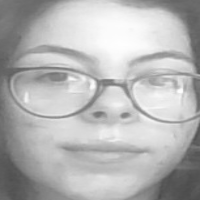

In [3]:
faces = []
labels = []
label_names = {}

face_model = YOLO("yolov8n-face.pt")

for label, name in enumerate(folders):
    folder = os.path.join(faces_folder, name)
    label_names[label] = name

    files = os.listdir(folder)

    for file in files:
        photo_path = os.path.join(folder, file)
        photo = cv2.imread(photo_path)

        if photo is None:
            continue

        face_result = face_model(photo, verbose=False)

        if len(face_result[0].boxes) == 0:
            continue

        left, top, right, bottom = face_result[0].boxes.xyxy[0].int()

        face = photo[top:bottom, left:right]
        face = cv2.cvtColor(face, cv2.COLOR_BGR2GRAY)
        face = cv2.resize(face, (200, 200))

        faces.append(face)
        labels.append(label)

Image.fromarray(faces[0])

## Training

Create an OpenCV LBPH face recognizer, train it using the processed faces and their numeric labels, then save the trained model to `face_recognizer.yml` so it can be loaded later for real-time recognition.

In [4]:
face_recognizer = cv2.face.LBPHFaceRecognizer_create()

face_recognizer.train(faces, np.array(labels))
face_recognizer.write("face_recognizer.yml")

## Inference

Run the trained face recognizer on a live webcam feed, display the predicted name and recognition distance, and label unfamiliar faces as `Unknown`.

> **Webcam note:** `cv2.VideoCapture(0)` uses camera device `0`, but your webcam index may be different. If the camera does not open, try `1`, `2`, or another available device number.

The default YOLO `face` label and confidence score are disabled here:

```python
processed_feed = face_result[0].plot(
    labels=False,
    conf=False
)
```

If you want to show YOLO's default face label and confidence again, comment out that block and uncomment:
```python
processed_feed = face_result[0].plot()
```

In [ ]:
cap = cv2.VideoCapture(0)

max_distance = 65

face_model = YOLO("yolov8n-face.pt")

face_recognizer = cv2.face.LBPHFaceRecognizer_create()
face_recognizer.read("face_recognizer.yml")

while cv2.waitKey(1) != ord("x"):
    _, frame = cap.read()

    face_result = face_model(frame, verbose=False) 
    # processed feed without the default face label
    processed_feed = face_result[0].plot(
        labels=False,
        conf=False
    )
    # processed feed with the default face label
    #processed_feed = face_result[0].plot()

    for box in face_result[0].boxes.xyxy:
        left, top, right, bottom = box.int()

        face = frame[top:bottom, left:right]
        face = cv2.cvtColor(face, cv2.COLOR_BGR2GRAY)
        face = cv2.resize(face, (200, 200))

        pred_label, distance = face_recognizer.predict(face)

        if distance > max_distance:
            name = "Unknown"
        else:
            name = label_names[pred_label]

        label_height = 30
        blue = (255, 0, 0)

        cv2.rectangle(
            processed_feed,
            (int(left) - 2, int(bottom)),
            (int(right) + 2, int(bottom) + label_height),
            blue,
            -1
        )

        cv2.putText(
            processed_feed,
            name + "  " + str(int(distance)),
            (int(left) + 2, int(bottom) + 20),
            0,
            0.6,
            (255, 255, 255),
            2
        )

    cv2.imshow("my window", processed_feed)

cv2.waitKey(5000)
cap.release()
cv2.destroyAllWindows()